[Data Grouping and Aggregation](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data%20aggregation.html) ended with a grouped result
indexed by continent and year, and a promise: turning it into a table with one column per
year is reshaping. The same information can be laid out with many rows and few columns, or
few rows and many columns, and different tasks need different layouts. A plot that colours
lines by group wants one layout; a comparison of two years side by side wants the other.

This chapter is about moving data between those layouts without changing a single value.
It covers turning a long table wide, turning a wide table long, and the checks that
confirm nothing was lost, duplicated, or quietly averaged along the way.

By the end of this chapter you should be able to:

- Tell long format from wide format, and say which one a task needs: plotting by group, comparing columns side by side, or summarizing.
- Turn long data wide with `pivot()` when each cell holds one value, with `pivot_table()` and an explicit `aggfunc` when several rows must be summarized, and with `unstack()` on a grouped result.
- Turn wide data long with `melt()` (`id_vars`, `var_name`, `value_name`) and with `stack()`.
- Check a reshape: count rows before and after, check what each `pivot_table()` cell combined, and restore column types that reshaping changes.

Complete the [practice activity](#practice-activity-long-wide-and-back)
after the worked examples.

## Set Up Your Chapter Files {#set-up-your-chapter-files}

Download the [Data Reshaping practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-reshaping-practice.zip).
Extract `stat303-data-reshaping` inside the `chapters` folder of your `stat303-1` course
folder, open `stat303-1` in VS Code, and select the course environment. The terminal
opens in `stat303-1`, so move it into the kit with `cd chapters` and then
`cd stat303-data-reshaping` before you render the activity.

```text
stat303-1/
├── .venv/
├── assignments/
└── chapters/
    └── stat303-data-reshaping/
        ├── data_reshaping_examples.ipynb
        ├── activity13.ipynb
        ├── README.md
        └── data/
            └── gdp_lifeExpectancy.csv
```

Run `data_reshaping_examples.ipynb` for the lesson and complete `activity13.ipynb` for
your own activity report, with `stat303-data-reshaping` as the notebook working folder.
The data is read with the relative path `"data/gdp_lifeExpectancy.csv"`, so the notebooks
find it only when that folder is the working folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Environment check:** This chapter uses NumPy, pandas, matplotlib, and seaborn, all of
which are already in the course environment. If an import fails, check the selected
notebook kernel first: it must be the course environment, `stat303-1/.venv`, as in
[Project Environments, Packages, and File Paths](https://lizhen0909.github.io/stat303-1-sec20-coursebook/python_venv.html#install-packages-in-the-intended-environment).

## What reshaping is

Reshaping changes the **structure** of a table without changing the information in it.
Think of rearranging the furniture in a room: every piece is still there, but the layout
suits a different purpose. The same values can be arranged in two basic layouts:

- **Long format** stacks the values into few columns and many rows. Each row is one
  observation: one country in one year, with its life expectancy.
- **Wide format** spreads the values across many columns and few rows. Each row is one
  unit, such as a country, with one column per year.

A small example with three countries and three years shows both. The data starts long:

In [2]:
toy_long = pd.DataFrame({
    "country": ["USA", "USA", "USA", "Canada", "Canada", "Canada", "Mexico", "Mexico", "Mexico"],
    "year": [2000, 2005, 2010] * 3,
    "lifeExp": [76.8, 77.5, 78.5, 79.2, 80.1, 81.0, 74.1, 75.2, 76.5],
})
toy_long

,country,year,lifeExp
0,USA,2000,76.8
1,USA,2005,77.5
2,USA,2010,78.5
3,Canada,2000,79.2
4,Canada,2005,80.1
5,Canada,2010,81.0
6,Mexico,2000,74.1
7,Mexico,2005,75.2
8,Mexico,2010,76.5


Nine rows, three columns. `pivot()`, explained fully below, turns the year values
into column headers:

In [3]:
toy_wide = toy_long.pivot(index="country", columns="year", values="lifeExp")
toy_wide

year,2000,2005,2010
country,,,
Canada,79.2,80.1,81.0
Mexico,74.1,75.2,76.5
USA,76.8,77.5,78.5


Three rows, three year columns, and the same nine values. The diagram follows one of
them, Canada in 2005, through the reshape in each direction:

![The same nine values in long and wide format. `pivot()` turns the year values into column headers; `melt()` turns the year columns back into rows. Canada's 2005 value, 80.1, is highlighted in both.](https://lizhen0909.github.io/stat303-1-sec20-coursebook/images/reshaping-long-wide.png){width=720}

| Format | Rows | Columns | Each row is | Suits |
|---|---|---|---|---|
| **Long** | 9 | 3 | One country in one year | Plotting by group, `groupby()`, statistical models |
| **Wide** | 3 | 3 | One country | Comparing years side by side, reading as a table |

::: {.callout-note}
## Tidy data

You will often see long format described as **tidy data**: each variable is a column,
each observation is a row, and each value is a cell. In the long table, `country`, `year`,
and `lifeExp` are each one column, and each row is one observation. In the wide table,
the single variable "year" is spread across three column headers. Tidy data is what
`groupby()`, seaborn, and most statistical tools expect, which is why data is so often
melted before it is analysed.
:::

**Why reshaping matters.**

- **Different tools need different layouts.** Seaborn's `hue=` and `col=`, from the
  visualization chapters, expect long data: one column holding the group. A comparison
  of 1957 with 2007 is one subtraction in wide data, with each year its own column.
- **Some calculations are easy in one layout and awkward in the other.** Change over time
  per country is a column difference when wide; a mean per year is a `groupby()` when
  long.
- **Combining datasets needs matching layouts.** Two tables can only be joined row by row
  once each row means the same thing in both, the subject of the next chapter.

| Direction | From a grouped result | From a table |
|---|---|---|
| Long → wide | `unstack()` | `pivot()`, or `pivot_table()` to summarize |
| Wide → long | `stack()` | `melt()` |

## The data

The rest of the chapter uses the Gapminder data from
[Data Grouping and Aggregation](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data%20aggregation.html): 142 countries every five years
from 1952 to 2007. It arrives in long format, one row per country-year:

In [4]:
gdp = pd.read_csv("data/gdp_lifeExpectancy.csv")
print(gdp.shape)
gdp.head()

(1704, 6)


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


## Long to wide

### Rearranging values: `pivot()`

[`pivot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html)
turns the values of one column into column headers. In the Gapminder data each country
has exactly one life expectancy per year, so a country-by-year table has one value for
each cell, and `pivot()` only has to move each value to its new place. `index=` takes a
list, so each row keeps its continent as well as its country:

In [5]:
country_wide = gdp.pivot(index=["continent", "country"], columns="year", values="lifeExp")
print(country_wide.shape)
country_wide.iloc[:3, :6].round(1)

(142, 12)


year               1952  1957  1962  1967  1972  1977
continent country                                    
Africa    Algeria  43.1  45.7  48.3  51.4  54.5  58.0
          Angola   30.0  32.0  34.0  36.0  37.9  39.5
          Benin    38.2  40.4  42.6  44.9  47.0  49.2

142 rows, one per country, and 12 year columns: 142 × 12 = 1,704 cells, one for each
row of `gdp`. The three arguments name the parts of the result:

| Argument | Becomes | Here |
|---|---|---|
| `index=` | The row labels | One row per country, labelled with its continent too |
| `columns=` | The column headers | One column per year |
| `values=` | What fills the cells | `lifeExp` |

Nothing is calculated: every number in the table is a number from `gdp`, moved to a new
position. That is what reshaping means.

### Why wide: two years side by side

With one row per country and one column per year, comparing any two years is easy. A
scatter plot of 1957 against 2007 shows every country's 50-year change at once.
`reset_index()` turns the two index levels back into columns for seaborn:

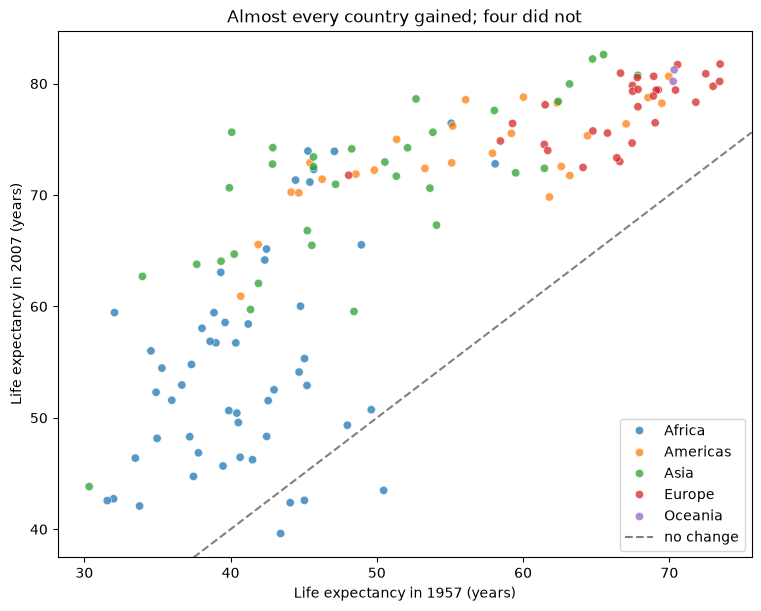

In [6]:
plot_data = country_wide.reset_index()

fig, ax = plt.subplots(figsize=(7.5, 6), layout="constrained")
sns.scatterplot(data=plot_data, x=1957, y=2007, hue="continent", alpha=0.75, ax=ax)
ax.axline((40, 40), slope=1, color="gray", linestyle="--", label="no change")
ax.set(xlabel="Life expectancy in 1957 (years)", ylabel="Life expectancy in 2007 (years)",
       title="Almost every country gained; four did not")
ax.legend(loc="lower right")
plt.show()

Points above the dashed line gained life expectancy over 50 years; points below it lost.
Selecting the countries below the line is one comparison of two columns:

In [7]:
declined = country_wide[country_wide[2007] < country_wide[1957]]
declined[[1957, 2007]].round(1)

year                 1957  2007
continent country              
Africa    Lesotho    45.0  42.6
          Swaziland  43.4  39.6
          Zambia     44.1  42.4
          Zimbabwe   50.5  43.5

Four countries, all in southern Africa — Lesotho, Swaziland, Zambia, and Zimbabwe — had
lower life expectancy in 2007 than in 1957. This is the region the HIV/AIDS epidemic of
the 1990s and 2000s hit hardest, and it is why Africa's average stalled in the last
chapter's trend plot. In long format, finding these four would take a filter, a
`groupby()`, and a comparison across rows; in wide format it is one line.

A wide table is also exactly what a heatmap draws, as in
[Data Visualization I](https://lizhen0909.github.io/stat303-1-sec20-coursebook/data_viz_1.html). Europe's 30 countries, each a row:

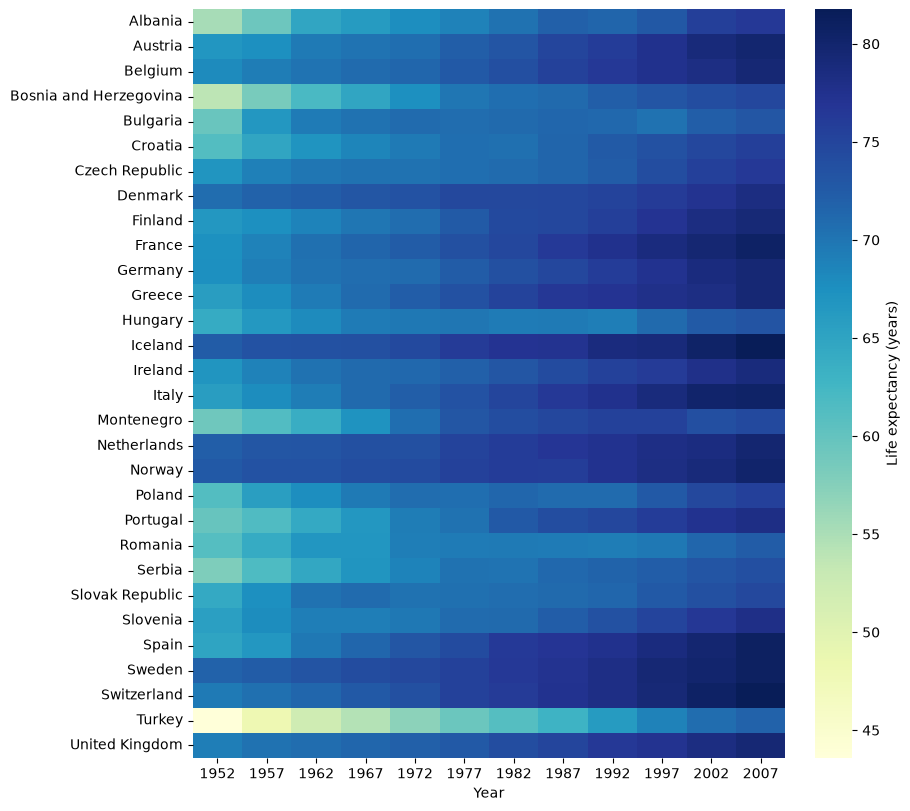

In [8]:
europe_wide = country_wide.loc["Europe"]

fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
sns.heatmap(europe_wide, cmap="YlGnBu", cbar_kws={"label": "Life expectancy (years)"}, ax=ax)
ax.set(xlabel="Year", ylabel="")
plt.show()

`country_wide.loc["Europe"]` selects one outer level of the two-level index, as in the
last chapter, leaving one row per European country. Each row darkens from left to right
as life expectancy rises. The lightest rows at the start — Turkey, Bosnia and
Herzegovina, and Albania — show where Europe's lowest life expectancies were in 1952.

::: {.callout-tip}
## Turning a wide table on its side

A wide table with many columns can be easier to read turned on its side. `.T`, the
transpose from [NumPy Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/numpy_fundamentals.html), swaps rows and columns:
`country_wide.T` has one row per year and one column per country. Unlike `pivot()`
and `melt()`, it does not change which values sit together; it only turns the table.
:::

### Summarizing while reshaping: `pivot_table()`

A continent-by-year table is a different request. Each continent-year cell would have to
hold every country of that continent in that year — 52 for Africa — and `pivot()` will not
choose among them:

In [9]:
try:
    gdp.pivot(index="continent", columns="year", values="lifeExp")
except ValueError as error:
    print("ValueError:", error)

ValueError: Index contains duplicate entries, cannot reshape


To fill such a cell, the rows that land in it must be summarized into one number, and
only you know which summary you want.
[`pivot_table()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot_table.html)
takes the same three arguments as `pivot()`, plus `aggfunc=`, the function that combines
the rows in each cell. Here it is the mean life expectancy of each continent's countries:

In [10]:
life_pivot = gdp.pivot_table(index="continent", columns="year",
                             values="lifeExp", aggfunc="mean")
life_pivot.round(1)

year,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007
continent,,,,,,,,,,,,
Africa,39.1,41.3,43.3,45.3,47.5,49.6,51.6,53.3,53.6,53.6,53.3,54.8
Americas,53.3,56.0,58.4,60.4,62.4,64.4,66.2,68.1,69.6,71.2,72.4,73.6
Asia,46.3,49.3,51.6,54.7,57.3,59.6,62.6,64.9,66.5,68.0,69.2,70.7
Europe,64.4,66.7,68.5,69.7,70.8,71.9,72.8,73.6,74.4,75.5,76.7,77.6
Oceania,69.3,70.3,71.1,71.3,71.9,72.9,74.3,75.3,76.9,78.2,79.7,80.7


Five rows and 12 year columns, each cell the mean over a continent's countries. The
fourth argument says how each cell is filled:

| Argument | Becomes | Here |
|---|---|---|
| `aggfunc=` | How the rows in each cell are combined | The mean |

::: {.callout-tip}
## Always name `aggfunc=`

`pivot_table()` has a default, the mean, so a call without `aggfunc=` still runs and
returns a table. But the code no longer says what the table holds: a reader, or you a week
later, cannot tell whether a mean was intended or whether a total was meant and forgotten.
Writing `aggfunc="mean"`, `aggfunc="sum"`, `aggfunc="median"`, or `aggfunc="count"` puts
the calculation in the code, where it can be checked. This book names it in every
`pivot_table()` call.
:::

A summary hides how many rows went into it. Asking for `aggfunc="count"` shows that:

In [11]:
gdp.pivot_table(index="continent", columns="year", values="lifeExp",
                aggfunc="count").iloc[:, :4]

year,1952,1957,1962,1967
continent,,,,
Africa,52,52,52,52
Americas,25,25,25,25
Asia,33,33,33,33
Europe,30,30,30,30
Oceania,2,2,2,2


Each Africa cell combines 52 countries, each Oceania cell two. Here the summarizing is
intended: each cell is meant to describe a continent.

`aggfunc=` takes any statistic name, or a lambda, as in `agg()` from the last chapter.
The 90th percentile of life expectancy among each continent's countries:

In [12]:
gdp.pivot_table(index="continent", columns="year", values="lifeExp",
                aggfunc=lambda x: x.quantile(0.9))[[1952, 2007]].round(1)

year,1952,2007
continent,,
Africa,45.0,71.3
Americas,65.4,78.7
Asia,60.0,79.7
Europe,71.9,80.9
Oceania,69.4,81.1


`margins=True` adds an `All` row and column. Notice what the `All` row averages:

In [13]:
life_margins = gdp.pivot_table(index="continent", columns="year", values="lifeExp",
                               aggfunc="mean", margins=True)
print("All row, 2007:", round(life_margins.loc["All", 2007], 1))
print("mean of the five continent means, 2007:", round(life_pivot[2007].mean(), 1))

All row, 2007: 67.0
mean of the five continent means, 2007: 71.5


The `All` row is the mean over all 142 countries, 67.0 years in 2007, not the mean of the
five continent means, 71.5. Africa's 52 countries count 26 times as much as Oceania's
two. It is the same question as in the last chapter — what does this mean average? —
and the margin answers it differently from what a reader of the table might assume.

### The same table from a grouped result: `unstack()`

The last chapter built this table in two steps. Grouping by two columns gives a Series
with a two-level index: continent on the outer level and year on the inner. `unstack()`
moves the inner level up into the column headers, so each continent becomes one row and
each year one column:

In [14]:
life_by_year = gdp.groupby(["continent", "year"])["lifeExp"].mean()
life_wide = life_by_year.unstack()
print(life_wide.equals(life_pivot))

True


`equals()` confirms the two tables are identical: `pivot_table()` does the grouping and the
unstacking in one call. Use `unstack()` when you already have a grouped result. Either
way, with years as columns, change over time is one subtraction:

In [15]:
(life_wide[2007] - life_wide[1952]).round(1).sort_values()

continent
Oceania     11.5
Europe      13.2
Africa      15.7
Americas    20.3
Asia        24.4
dtype: float64

Africa gained 15.7 years over the period and Asia 24.4.

### Rearrange or summarize? What a duplicate does

The choice between `pivot()` and `pivot_table()` matters most when the data has a mistake.
Suppose the three-country table had Canada's 2005 value entered twice, with a typo in the
second entry. `pd.concat()`, from [Pandas Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/pandas_fundamentals.html), adds
the extra row; `ignore_index=True` numbers the rows afresh. `pivot()` stops at the
duplicate:

In [16]:
toy_dup = pd.concat([toy_long,
                     pd.DataFrame({"country": ["Canada"], "year": [2005], "lifeExp": [80.5]})],
                    ignore_index=True)

try:
    toy_dup.pivot(index="country", columns="year", values="lifeExp")
except ValueError as error:
    print("ValueError:", error)

ValueError: Index contains duplicate entries, cannot reshape


`pivot_table()` does not stop. It does what it was told, and averages the two rows:

In [17]:
toy_dup.pivot_table(index="country", columns="year", values="lifeExp", aggfunc="mean")

year,2000,2005,2010
country,,,
Canada,79.2,80.3,81.0
Mexico,74.1,75.2,76.5
USA,76.8,77.5,78.5


The table looks complete, and Canada's 2005 cell says 80.3: a value that appears nowhere
in the data, the mean of 80.1 and 80.5. Nothing warns you. The counts do:

In [18]:
toy_dup.pivot_table(index="country", columns="year", values="lifeExp", aggfunc="count")

year,2000,2005,2010
country,,,
Canada,1,2,1
Mexico,1,1,1
USA,1,1,1


One cell holds 2. So the rule is: when each cell should hold one value, use `pivot()`,
which stops at a duplicate. When you mean to summarize, use `pivot_table()`, name the
summary in `aggfunc=`, and check the counts if any cell should have held one row. A
duplicate is the kind of row `duplicated(subset=["country", "year"])` from
[Data Cleaning](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_cleaning.html) finds before you reshape.

## Wide to long

### `melt()`

Data often arrives wide because that is how people record and publish it: a spreadsheet
with one row per student and one column per quiz, or a public data download — from the
World Bank or the Census Bureau, say — with one row per country or state and one column
per year. With such data, `melt()` is usually the first step.
[`melt()`](https://pandas.pydata.org/docs/reference/api/pandas.melt.html) turns those
columns into rows, the inverse of pivoting. A small gradebook shows the idea:

In [19]:
grades = pd.DataFrame({
    "student": ["Ana", "Ben", "Chen", "Dee"],
    "quiz1": [8, 6, 9, 7],
    "quiz2": [9, 7, 9, 6],
    "quiz3": [7, 8, 10, 8],
})
grades

,student,quiz1,quiz2,quiz3
0,Ana,8,9,7
1,Ben,6,7,8
2,Chen,9,9,10
3,Dee,7,6,8


In [20]:
grades_long = grades.melt(id_vars="student", var_name="quiz", value_name="score")
grades_long

,student,quiz,score
0,Ana,quiz1,8
1,Ben,quiz1,6
2,Chen,quiz1,9
3,Dee,quiz1,7
4,Ana,quiz2,9
5,Ben,quiz2,7
6,Chen,quiz2,9
7,Dee,quiz2,6
8,Ana,quiz3,7
9,Ben,quiz3,8


Four students × three quizzes = 12 rows. The three arguments say what to keep and what to
call the new columns:

| Argument | Meaning | Here |
|---|---|---|
| `id_vars=` | Columns that identify a row and stay as they are | `student` |
| `var_name=` | Name for the new column that holds the old column headers | `quiz` |
| `value_name=` | Name for the new column that holds the values | `score` |

Every column not listed in `id_vars` is melted; `value_vars=` limits the melt to some of
them. In long form, the questions a gradebook raises become one familiar line each — the
mean score on each quiz is a `groupby()`:

In [21]:
grades_long.groupby("quiz")["score"].mean()

quiz
quiz1    7.50
quiz2    7.75
quiz3    8.25
Name: score, dtype: float64

Long format is also what seaborn's `hue=` needs, here to draw one line per student:

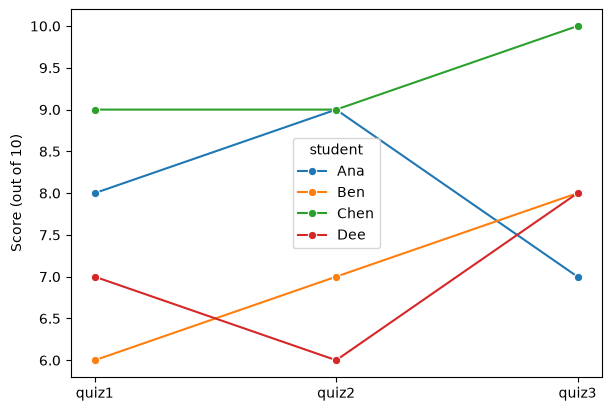

In [22]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
sns.lineplot(data=grades_long, x="quiz", y="score", hue="student", marker="o", ax=ax)
ax.set(xlabel="", ylabel="Score (out of 10)")
plt.show()

### Melting back, and checking the result

The country-by-year table melts back into the original long layout. `reset_index()`
first turns `continent` and `country` into ordinary columns, so they can be `id_vars`:

In [23]:
life_long = country_wide.reset_index().melt(id_vars=["continent", "country"],
                                           var_name="year", value_name="lifeExp")
print(life_long.shape)
print(life_long.dtypes)

(1704, 4)
continent        str
country          str
year          object
lifeExp      float64
dtype: object


142 countries × 12 years = 1,704 rows, matching the original data. But `year` came back as
`object`, not as integers: the year labels passed through column headers, where they
were stored alongside the text headers `continent` and `country`. A reshape can change a
column's type without any warning, so check `dtypes` afterwards and restore it:

In [24]:
life_long["year"] = life_long["year"].astype(int)

original = gdp.sort_values(["country", "year"]).reset_index(drop=True)
restored = life_long.sort_values(["country", "year"]).reset_index(drop=True)
print("same years:", (original["year"] == restored["year"]).all())
print("same values:", np.allclose(original["lifeExp"], restored["lifeExp"]))

same years: True
same values: True


Sorted the same way, the melted table matches the original row for row: long to wide and
back again lost nothing. This **round-trip check** — reshape, reshape back, compare — is
the surest way to confirm a reshape did only what you meant.

### `stack()`

`stack()` is the counterpart of `unstack()`: it moves the column headers down into the
inner level of the row index, turning the continent-by-year table back into a Series:

In [25]:
life_stacked = life_wide.stack()
print(life_stacked.shape)
life_stacked.head()

(60,)


continent  year
Africa     1952    39.135500
           1957    41.266346
           1962    43.319442
           1967    45.334538
           1972    47.450942
dtype: float64

60 values again, indexed by continent and year: exactly the grouped result the section
started from. Use `stack()` and `unstack()` when the data already has a two-level index,
as grouped results do, and `melt()`, `pivot()`, and `pivot_table()` when it has ordinary columns.

## Summary Cheat Sheet {#summary-cheat-sheet}

| Goal | Code |
|---|---|
| Long table to wide, one value per cell | `df.pivot(index="a", columns="b", values="v")` |
| Long table to wide, summarizing each cell | `df.pivot_table(index="a", columns="b", values="v", aggfunc="mean")` |
| Grouped result to wide | `df.groupby(["a", "b"])["v"].mean().unstack()` |
| Several row labels | `pivot(index=["a", "c"], ...)`, and the same in `pivot_table()` |
| See how many rows each cell combined | `pivot_table(..., aggfunc="count")` |
| Your own statistic | `aggfunc=lambda x: x.quantile(0.9)` |
| Totals or overall means | `pivot_table(..., margins=True)` |
| Wide table to long | `df.melt(id_vars="id", var_name="name", value_name="value")` |
| Melt only some columns | `melt(..., value_vars=["c1", "c2"])` |
| Wide with a two-level index to long | `wide.stack()` |
| Index levels back to columns | `reset_index()` |
| Restore a type changed by reshaping | `df["year"] = df["year"].astype(int)` |
| Swap rows and columns | `df.T` |

The rule to remember: **after every reshape, check the number of rows, what each cell
combined, and the column types,** and name `aggfunc=` whenever a cell summarizes several rows.

## Practice Activity: Long, Wide, and Back {#practice-activity-long-wide-and-back}

**Goal:** Reshape one dataset in both directions, use each layout for what it does best, and check that nothing was lost or quietly averaged.

**File:** `activity13.ipynb` from the [practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-reshaping-practice.zip).

**Submit:** `activity13.html` through the final upload question in the Data Reshaping Canvas quiz.

**This section contains the complete activity instructions.** The starter loads the data and supplies spaces to record your work. Open `activity13.ipynb` from the folder prepared in [Set Up Your Chapter Files](#set-up-your-chapter-files), using the same project environment. The worked examples above are preparation, not additional submission requirements.

The starter loads `gdp` from the kit's `data/` folder and builds a small wide table, `rainfall`, with one row per city and one column per month.

### A. Long to Wide, Two Ways {.unnumbered}

- Replace `Your Name` in the opening Raw cell's `author` field. Run the setup cell; it must report the shapes `(1704, 6)` and `(4, 5)`.
- Build a continent-by-year table of median `gdpPercap` twice: once with `groupby()` and `unstack()`, once with `pivot_table()` and `aggfunc="median"`. Show that the two are identical with `equals()`.
- Say in one sentence how many countries went into the Africa cells, and how you checked.

### B. Compare Two Years {.unnumbered}

- Build a country-by-year table of `gdpPercap` with `pivot()` and compute each country's ratio of 2007 to 1957 GDP per capita.
- Show the five countries with the largest ratio, and report how many countries had lower GDP per capita in 2007 than in 1957.

### C. Wide to Long, and Check {.unnumbered}

- Melt `rainfall` into a long table with columns `city`, `month`, and `rainfall_mm`. Confirm the number of rows is the number of cities times the number of months.
- Use the long table to compute mean rainfall per month with `groupby()`, and draw one line per city with seaborn.

### D. When a Pivot Summarizes {.unnumbered}

- Build a continent-by-year table of `pop` with `aggfunc="sum"`, and another with the default `aggfunc`.
- Say which table answers "how many people lived in each continent?", and what the other one actually shows.

### Render and Submit {.unnumbered}

Restart the kernel, run all cells in order, resolve unexpected errors, and save. Include your outputs and explanations for A–D, and a short Markdown completion note. From `stat303-data-reshaping` in the terminal, run:

```text
quarto render activity13.ipynb --to html
```

Follow the [Quarto refresher](https://lizhen0909.github.io/stat303-1-sec20-coursebook/vscode_setup.html#render-and-submit-with-quarto): inspect the HTML and a copy opened outside the project folder, and confirm that every output appears and your name is on the report. Upload only `activity13.html` to the Data Reshaping Canvas quiz; keep your notebook locally.

**HTML grading (16 points):** both wide tables, the `equals()` check, and the count explanation (4); the country-by-year table, the five largest ratios, and the count of declines (4); the melted table with its row check, the monthly means, and the plot (4); both population tables and the explanation (3); name, readable report, and completion note (1).

## Extended Practice {#extended-practice}

These longer exercises are additional practice, not requirements for the Canvas quiz.
Work in a separate notebook beside your activity and load the data the way the chapter
does. Include your code, outputs, and explanations.

### Several Values at Once

Pass two columns to `values=`, as in `pivot_table(index="continent", columns="year",
values=["lifeExp", "gdpPercap"], aggfunc="mean")`. The result has two-level column headers. Select the
`gdpPercap` block, then try `stack()` on the result. Which layout would you hand to a
reader, and which to seaborn?

### A Heatmap of Change

Build the country-by-year table of `lifeExp` for Africa, subtract the 1952 column from
every column, and draw the result as a heatmap with a diverging colour map centred at 0.
Which countries stand out, and in which decades?

### Melt Only Part of a Table

Starting from the country-by-year table, melt only the columns 1952, 1977, and 2007 with
`value_vars=`. How many rows does the result have, and what happened to the other years?

### Round Trip on GDP

Repeat the chapter's round-trip check for `gdpPercap`: pivot to wide, melt back, restore
the type, and confirm with `np.allclose()` that every value matches the original.

## Before You Move On {#before-you-move-on}

The habit to carry forward is checking a reshape. Every tool in this chapter can return
a perfectly shaped table that is wrong: `pivot_table()` averages a duplicate without saying so,
`margins=True` averages over rows rather than groups, and `melt()` can bring numbers back
as text. Count the rows, look at what each cell combined, and check the types — or reshape
back and compare.

Choose `pivot()` when each cell should hold one value, so a duplicate stops it, and
`pivot_table()` with a named `aggfunc=` when you mean to summarize.

The other habit is choosing the layout by the task. Long data suits `groupby()`, seaborn,
and models; wide data suits comparisons between columns and tables for a reader.

For any reshape you make, you should be able to answer five questions:

1. Is the starting table long or wide, and what is one row?
2. What will one row and one column be after the reshape?
3. Did any cell combine more than one value, and if so, how?
4. Does the row count after the reshape match what you expected?
5. Did any column change type?

Continue to [Combining Datasets](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data%20wrangling.html), where tables in matching layouts
are joined together.

References: [pandas: reshaping and pivot tables](https://pandas.pydata.org/docs/user_guide/reshaping.html),
[`DataFrame.pivot`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html),
[`DataFrame.pivot_table`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot_table.html),
[`DataFrame.melt`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.melt.html),
[`DataFrame.stack`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.stack.html),
[`DataFrame.unstack`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.unstack.html),
and [`DataFrame.T`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html).